### Training and Visualizing a Decision Tree

In [1]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

In [2]:
iris = load_iris(as_frame=True)

In [3]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [4]:
X = iris.data[['petal length (cm)', 'petal width (cm)']].values
y = iris.target

Don't apply scaling for trees

In [5]:
tree_clf = DecisionTreeClassifier(max_depth=2,random_state=42)
tree_clf.fit(X,y)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [ ]:
# from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
# def cal_accuracy(y_test, y_pred):
#     print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
#     print("\nAccuracy:", accuracy_score(y_test, y_pred) * 100)
#     print("\nClassification Report:\n", classification_report(y_test, y_pred))

In [9]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

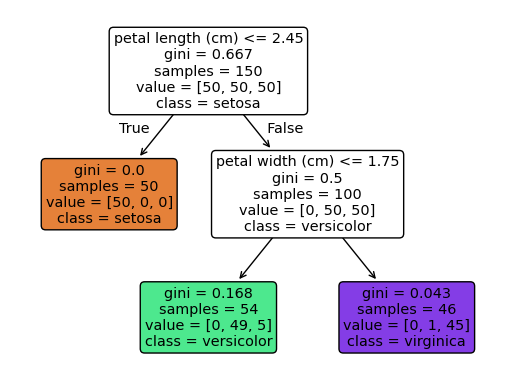

In [14]:
plot_tree(tree_clf,feature_names=["petal length (cm)", "petal width (cm)"],class_names=iris.target_names,filled=True,rounded=True)
plt.show()

In [16]:
tree_clf.predict_proba([[5,1.5]]).round(2)

array([[0.  , 0.91, 0.09]])

In [17]:
tree_clf.predict([[5,1.5]])

array([1])

### Regularization Hyperparameters

In [18]:
from sklearn.datasets import make_moons

In [19]:
X_moons, y_moons = make_moons(n_samples=150, noise=0.2, random_state=42)

In [20]:
tree_clf1 = DecisionTreeClassifier(random_state=42)
tree_clf2 = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)

tree_clf1.fit(X_moons,y_moons)
tree_clf2.fit(X_moons,y_moons)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [21]:
# test data
X_moons_test, y_moons_test = make_moons(n_samples=1000, noise=0.2, random_state=43)
# score
print(tree_clf1.score(X_moons_test, y_moons_test))
print(tree_clf2.score(X_moons_test, y_moons_test))

0.898
0.92


### Regression

In [23]:
import numpy as np
np.random.seed(42)

In [24]:
X_quad = np.random.rand(200, 1) - 0.5 # a single random input feature
y_quad = X_quad ** 2 + 0.025 * np.random.randn(200, 1)

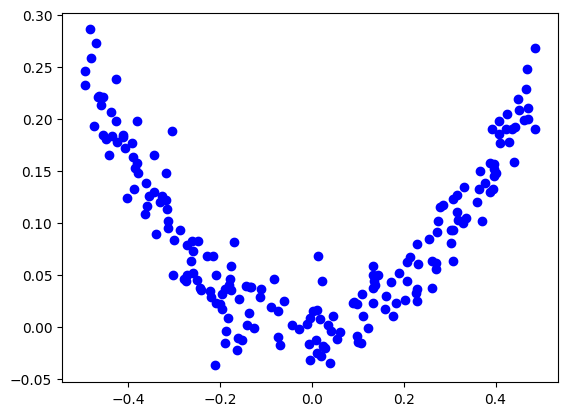

In [27]:
plt.plot(X_quad,y_quad,"bo")
plt.show()

In [25]:
from sklearn.tree import DecisionTreeRegressor

In [31]:
tree_reg = DecisionTreeRegressor(max_depth=2,random_state=42)
tree_reg.fit(X_quad,y_quad)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


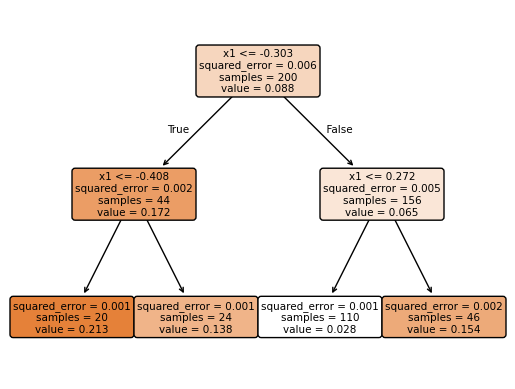

In [32]:
plot_tree(tree_reg,feature_names=["x1"],filled=True,rounded=True)
plt.show()

In [33]:
tree_reg.tree_.threshold

array([-0.30265072, -0.40830374, -2.        , -2.        ,  0.27175756,
       -2.        , -2.        ])

### Sensitivity to Axis Orientation

Let’s create a small pipeline that scales the data and rotates it using PCA,
then train a DecisionTreeClassifier on that data

In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [36]:
pca_pipeline = make_pipeline(
    StandardScaler(),
    PCA()
)
X_rotated = pca_pipeline.fit_transform(X)

In [37]:
tree_clf_pca = DecisionTreeRegressor(max_depth=2,random_state=42)
tree_clf_pca.fit(X_rotated,y)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0
